Runs found: ['deeplabv3plus_train10_VV-VH-RATIO_s42', 'deeplabv3plus_train40_VV-VH-RATIO_s42', 'fpn_train10_VV-VH-RATIO_s42', 'fpn_train40_VV-VH-RATIO_s42', 'segformer_train10_VV-VH-RATIO_s42', 'segformer_train40_VV-VH-RATIO_s42', 'segformer_trainmix_VV-VH-RATIO_s42', 'unet_train10_VV-VH-RATIO_s42', 'unet_train40_VV-VH-RATIO_s42', 'unet_trainmix_VV-VH-RATIO_s42']


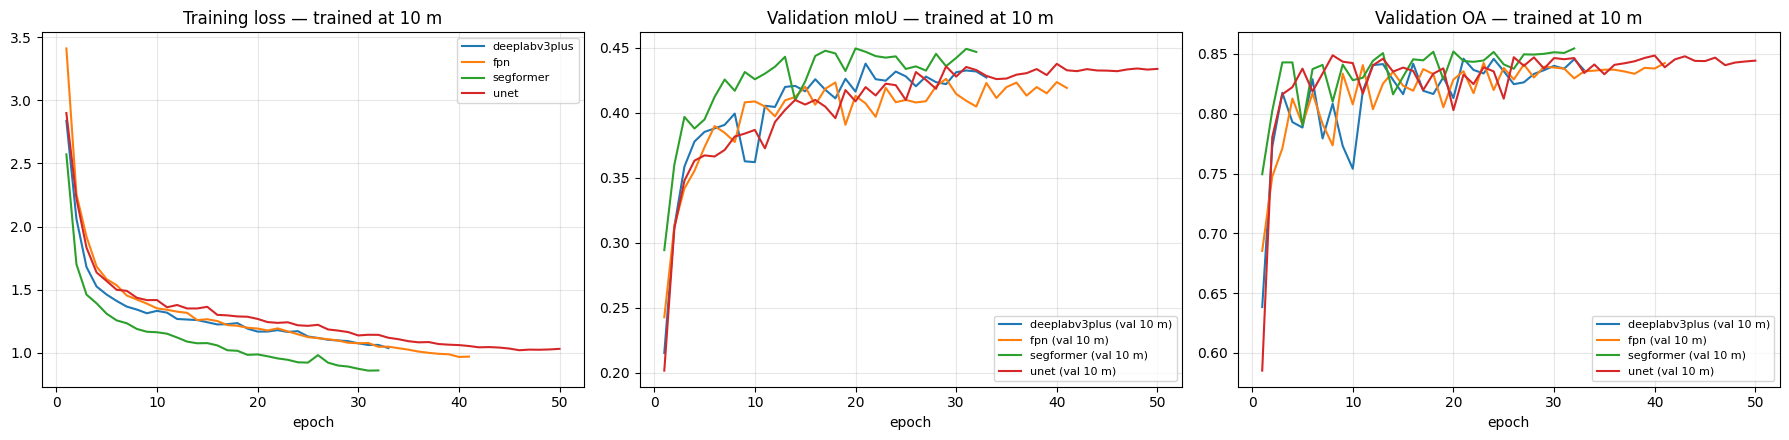

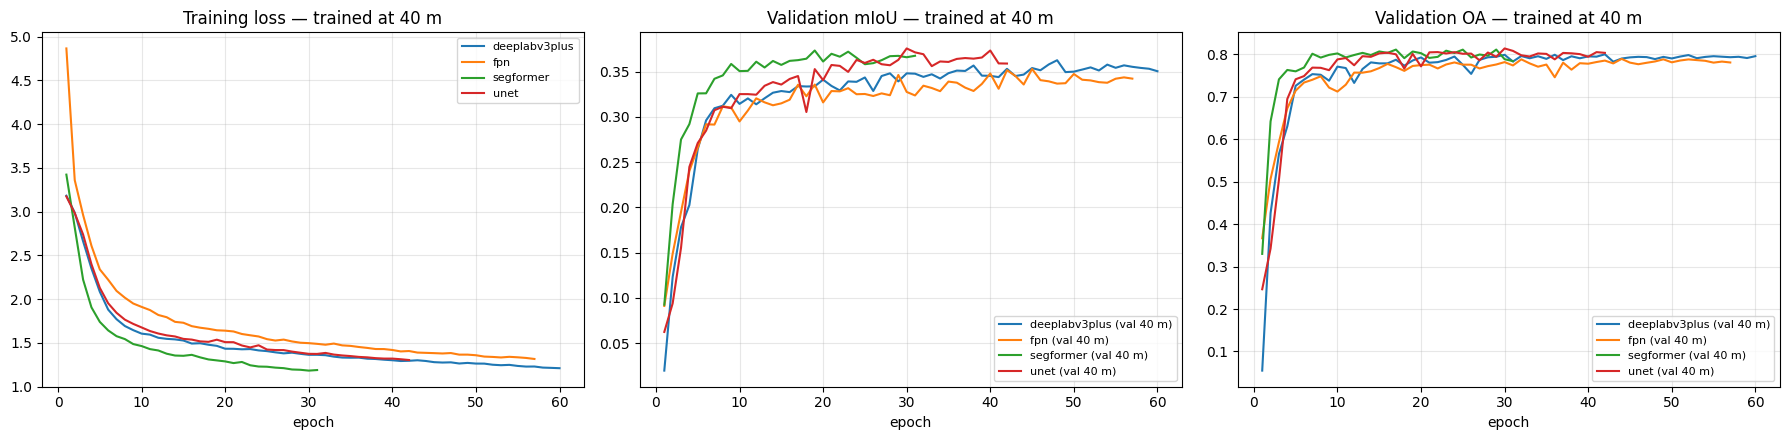

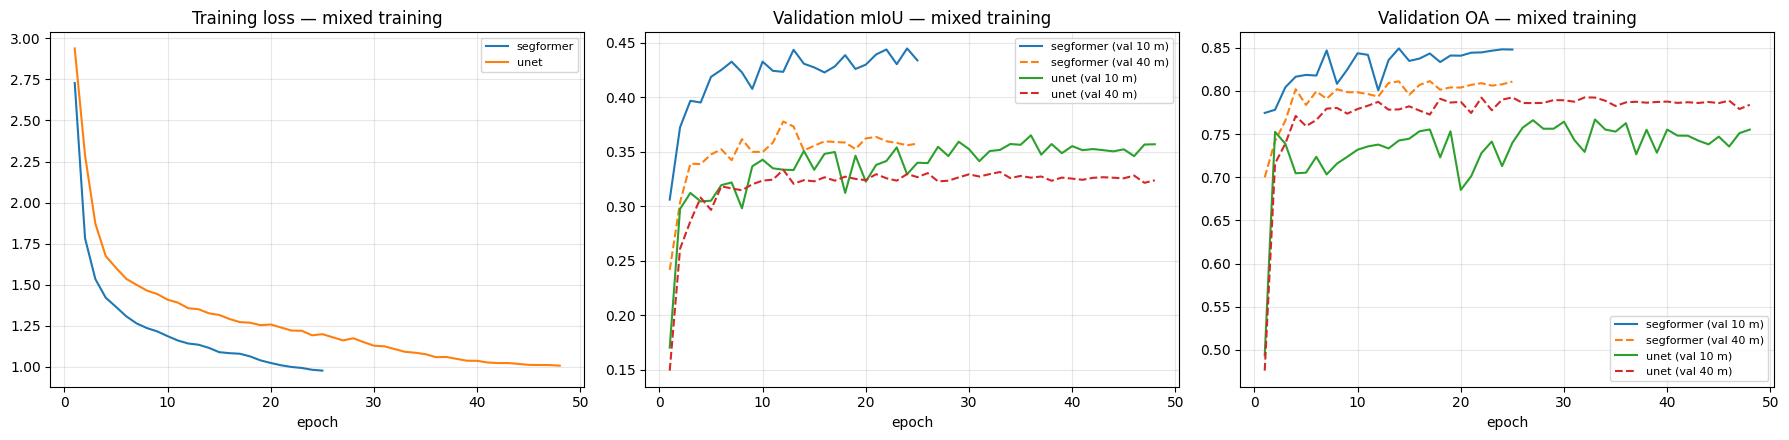

                                  run  epochs_done  best_epoch  best_val_mIoU  sec_per_epoch
deeplabv3plus_train10_VV-VH-RATIO_s42           33          21         0.4378          129.9
deeplabv3plus_train40_VV-VH-RATIO_s42           60          48         0.3625            3.1
          fpn_train10_VV-VH-RATIO_s42           41          29         0.4262          130.2
          fpn_train40_VV-VH-RATIO_s42           57          45         0.3529            3.2
    segformer_train10_VV-VH-RATIO_s42           32          20         0.4495          138.5
    segformer_train40_VV-VH-RATIO_s42           31          19         0.3733            4.1
   segformer_trainmix_VV-VH-RATIO_s42           25          13         0.4085           55.4
         unet_train10_VV-VH-RATIO_s42           50          40         0.4377          130.4
         unet_train40_VV-VH-RATIO_s42           42          30         0.3756            3.2
        unet_trainmix_VV-VH-RATIO_s42           48          36        

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

PROJ = "/home/jovyan/vault/heidelberg_lulc_2025"
FIG = f"{PROJ}/outputs/figures"
os.makedirs(FIG, exist_ok=True)

hist = {}
for p in sorted(glob.glob(f"{PROJ}/logs/*/history.csv")):
    run = os.path.basename(os.path.dirname(p))
    if not run.startswith("smoke_"):
        hist[run] = pd.read_csv(p)
print("Runs found:", list(hist))

groups = {"10": [r for r in hist if "_train10_" in r],
          "40": [r for r in hist if "_train40_" in r],
          "mix": [r for r in hist if "_trainmix_" in r]}

for g, runs in groups.items():
    if not runs:
        continue
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
    for r in runs:
        h = hist[r]
        name = r.split("_train")[0]
        axs[0].plot(h.epoch, h.train_loss, label=name)
        for res in ("10", "40"):
            if f"val{res}_miou" in h:
                ls = "-" if res == ("40" if g == "40" else "10") else "--"
                axs[1].plot(h.epoch, h[f"val{res}_miou"], ls, label=f"{name} (val {res} m)")
                axs[2].plot(h.epoch, h[f"val{res}_oa"], ls, label=f"{name} (val {res} m)")
    for ax, t in zip(axs, ["Training loss", "Validation mIoU", "Validation OA"]):
        ax.set_title(f"{t} — trained at {g} m" if g != "mix" else f"{t} — mixed training")
        ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{FIG}/training_curves_train{g}.png", dpi=150)
    plt.show()

rows = []
for r, h in hist.items():
    b = h.loc[h.select_score.idxmax()]
    rows.append({"run": r, "epochs_done": len(h), "best_epoch": int(b.epoch),
                 "best_val_mIoU": round(b.select_score, 4), "sec_per_epoch": round(h.epoch_sec.median(), 1)})
print(pd.DataFrame(rows).to_string(index=False))